# Load libraries

In [1]:
import numpy as np
import itertools, pandas as pd
from models import LinearModel, ChoquetModel, LipschitzModel
from tests import (
    ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2,
    ZDT1_Shifted, ZDT2_Shifted, ZDT2_Combined,
    Kursawe, Fon, Sch1, Sch2,
    Ackley01, Schwefel04, Gulf,
    ExtendedProblem, WFG
)

from agg import (
    Product, Drastic, Lukasiewicz,
    SchweizerSklar, Frank,
    QAM, ConjunctiveThreePi
)

import matplotlib.pyplot as plt
from utils import evaluate, visualise_weights

# Modelling: Problems

## ZDT & DTLZ

In [2]:
# ZDT calling
# linear_model = LinearModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# # DTLZ calling
# linear_model = LinearModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42)
# choquet_model = ChoquetModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [3]:
# Self-constructed calling
# linear_model = LinearModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Swapped(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [4]:
# extended_problem = ExtendedProblem(
#     problems = [ZDT2(n_dim = 5),
#                 Drastic([ZDT2(n_dim = 5)]),
#                 ],
#     order = None)

In [5]:
# linear_model = LinearModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = extended_problem, max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = extended_problem, max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = extended_problem, max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [6]:
# WFG calling
linear_model = LinearModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42, solver = "Powell")
choquet_model = ChoquetModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42, method = 2, solver = "Powell")
slip_model = LipschitzModel(problem = WFG(name = "wfg1", n_dim = 10, n_obj = 2), max_iter = 5, random_state = 42, solver = "Powell",
                            type = "global_mon", num_k = 2)

# Modelling: Solve

In [7]:
# Let them solve
linear_model.solve()
choquet_model.solve()
slip_model.solve()

# Summary their performance metrics

print(f"LinearModel :  PF {linear_model.PF.shape}  PS {linear_model.PS.shape}")
print(f"ChoquetModel:  PF {choquet_model.PF.shape} PS {choquet_model.PS.shape}")
print(f"LipschitzModel:  PF {slip_model.PF.shape} PS {slip_model.PS.shape}")
evaluate([linear_model, choquet_model, slip_model])

/Users/admin/Deakin/Year_3/T2:2026/SIT316 - Linear And Nonlinear Optimisation/Portfolio/HD Project/src/models.py:242: OptimizeWarning: Unknown solver options: eps
  self._search(lambda: minimize(self.F, x, args = (self.w,), method = self.solver,  # solve using scalarised F


LinearModel :  PF (5232, 2)  PS (5232, 10)
ChoquetModel:  PF (6862, 2) PS (6862, 10)
LipschitzModel:  PF (149, 2) PS (149, 10)


,hypervolume,n_func_eval,n_non_dominated,n_iter,wallclock_time
LinearModel,0.321260,60075,5232,5,23.014573
ChoquetModel,1.147040,67106,6862,5,341.882726
LipschitzModel,1.798718,92091,149,5,147.971895


# Model visualisation

In [8]:
# for kind in ["symmetric", "absolute", "norm"]:
#     visualise_weights(choquet_model, kind = kind);

In [9]:
# linear_model.visualise("true_pf");

## Linear Model

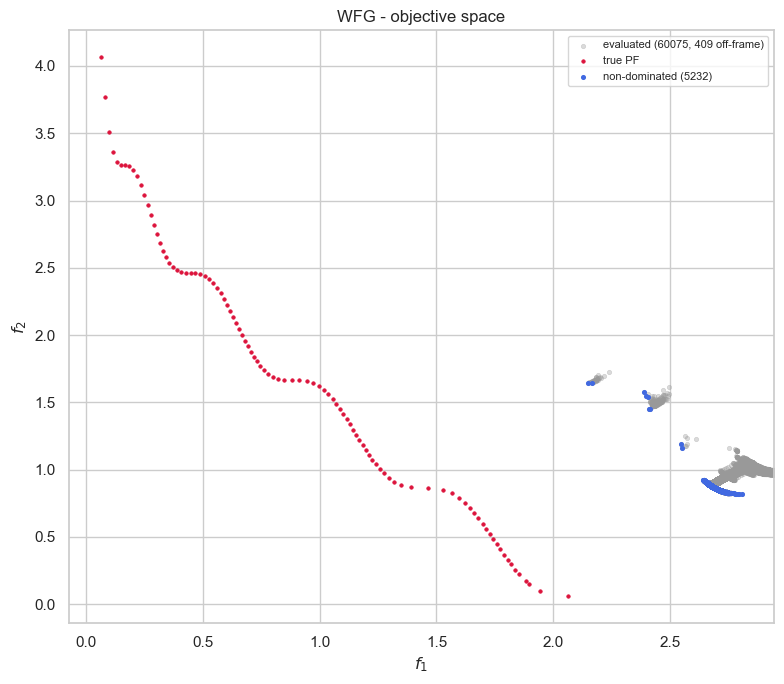

In [10]:
linear_model.visualise("objective");

In [11]:
linear_model.visualise("learning", show = False)

In [12]:
linear_model.visualise("learning", plot_scalarisation = True, show = False)

## Choquet Model

In [13]:
np.all((choquet_model.dec_hist >= 0) & (choquet_model.dec_hist <= 1))

np.True_

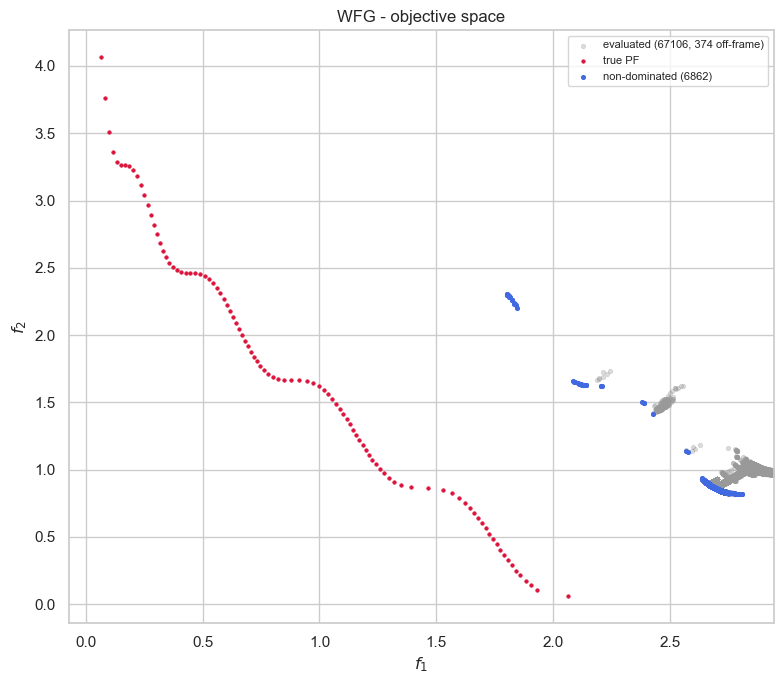

In [14]:
choquet_model.visualise("objective");

In [15]:
choquet_model.visualise("learning", show = False)

In [16]:
choquet_model.visualise("learning", plot_scalarisation = True, show = False)

## Lipschitz Model

In [17]:
np.all((slip_model.dec_hist >= 0) & (slip_model.dec_hist <= 1))

np.True_

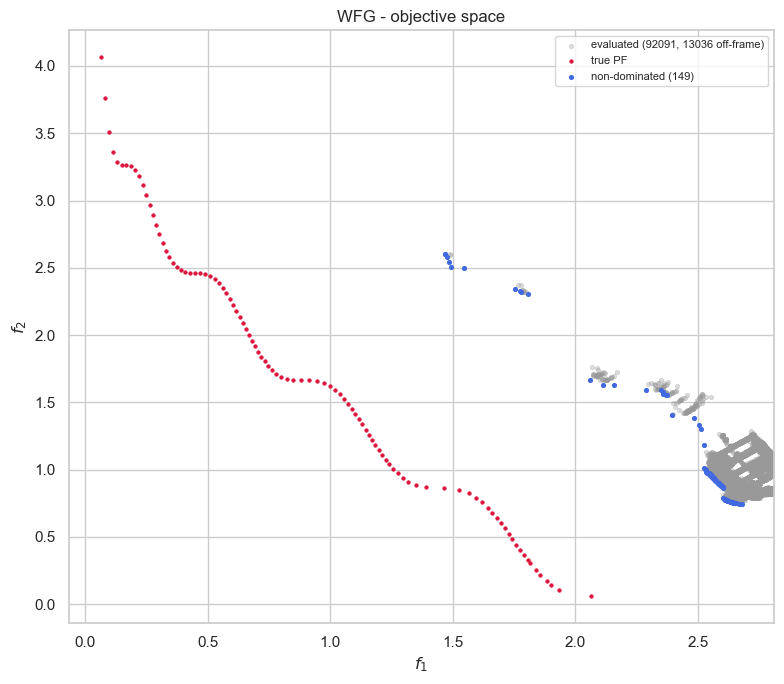

In [18]:
slip_model.visualise("objective");

In [19]:
slip_model.visualise("learning", show = False)

In [20]:
slip_model.visualise("learning", plot_scalarisation = True, show = False)

# Pareto Front and Pareto Set statistics

This section displays the statistics of the Pareto front and Pareto set found by the above-mentioned models. Note that, these are the set of non-dominated solutions, not all the iterates obtained throughout their runs.

In [21]:
import seaborn as sns


def plot_distributions(arrays, symbol, title):
    """Box plot and per-component ECDFs of each model's points; arrays maps model name -> (n_points, n_components)."""
    long = pd.concat(
        [pd.DataFrame(a).rename(columns = lambda k: f"${symbol}_{{{k + 1}}}$")
           .melt(var_name = "component", value_name = "value")
           .assign(model = f"{name} (n={len(a)})")
         for name, a in arrays.items()],
        ignore_index = True,
    )
    n_comp = long["component"].nunique()

    fig, ax = plt.subplots(figsize = (max(6, 1.6 * n_comp), 4))
    sns.boxplot(data = long, x = "component", y = "value", hue = "model", ax = ax,
                fliersize = 2, linewidth = 0.8)
    ax.set(xlabel = None, ylabel = f"${symbol}$", title = f"{title}: distribution per component")
    sns.move_legend(ax, "upper left", bbox_to_anchor = (1, 1), frameon = False)
    plt.show()

    g = sns.displot(long, x = "value", hue = "model", col = "component", kind = "ecdf",
                    col_wrap = min(n_comp, 5), height = 2.8, aspect = 1)
    g.set_titles("{col_name}")
    g.set_axis_labels(f"${symbol}$", "ECDF")
    g.figure.suptitle(f"{title}: empirical CDF per component", y = 1.04)
    plt.show()

## Pareto Front

In [22]:
# arr = {
#     "baseline": linear_model.PF,
#     "cas": choquet_model.PF,
#     "las": slip_model.PF
# }

arr = {
    "baseline": linear_model.obj_hist,
    "cas": choquet_model.obj_hist,
    "las": slip_model.obj_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                         cas                         las  \
k                 0             1             0             1             0   
count  60075.000000  60075.000000  67106.000000  67106.000000  92091.000000   
mean       2.745637      0.942785      2.750210      0.926379      2.724322   
std        0.076684      0.070481      0.077873      0.071222      0.085877   
min        2.149952      0.821036      1.801267      0.821021      1.466496   
25%        2.686582      0.891061      2.695218      0.876216      2.676653   
50%        2.707927      0.912362      2.715898      0.904768      2.725028   
75%        2.811482      0.999411      2.817881      0.983951      2.774043   
max        2.983461      1.724164      2.983461      2.305181      2.983461   

model                
k                 1  
count  92091.000000  
mean       0.946101  
std        0.105234  
min        0.742250  
25%        0.861086  
50%        0.901762  
75%        1.021519  
max        2.605962

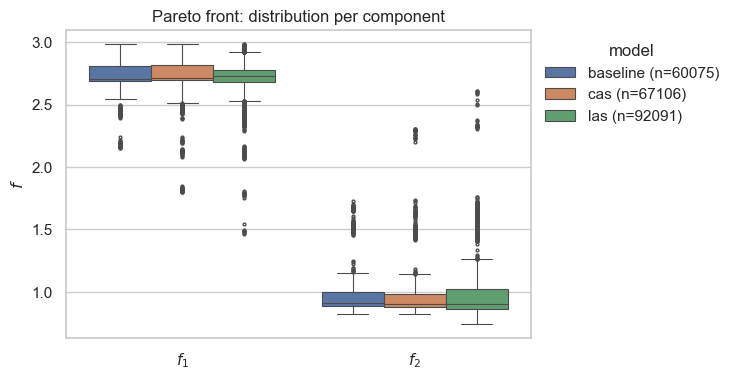

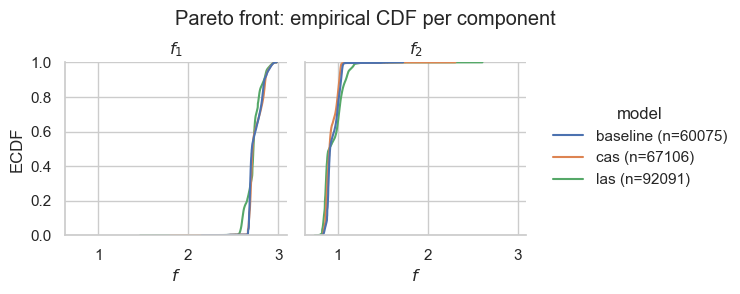

In [23]:
plot_distributions(arr, "f", "Pareto front")

## Pareto Set

In [24]:
# arr = {
#     "baseline": linear_model.PS,
#     "cas": choquet_model.PS,
#     "las": slip_model.PS
# }

arr = {
    "baseline": linear_model.dec_hist,
    "cas": choquet_model.dec_hist,
    "las": slip_model.dec_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                                                          \
k                 0             1             2             3             4   
count  60075.000000  60075.000000  60075.000000  60075.000000  60075.000000   
mean       0.031329      0.099739      0.484026      0.501318      0.378131   
std        0.129377      0.213876      0.278368      0.292734      0.144577   
min        0.000000      0.000000      0.003956      0.001186      0.004741   
25%        0.000400      0.000733      0.240819      0.236068      0.349983   
50%        0.000400      0.006242      0.472784      0.514223      0.349983   
75%        0.000400      0.064284      0.728968      0.756421      0.349983   
max        1.000000      1.000000      0.999687      0.993599      0.997035   

model                                                                        \
k                 5             6             7             8             9   
count  60075.000000  60075.000000  60075.000000  60075.000000  60075.000000   
mean       0.387288      0.394196      0.400919      0.411247      0.420427   
std        0.152974      0.162105      0.177065      0.196406      0.200627   
min        0.009260      0.000000      0.000519      0.014683      0.000000   
25%        0.349983      0.349983      0.349983      0.349983      0.349983   
50%        0.349983      0.349983      0.349983      0.349983      0.349983   
75%        0.349983      0.350316      0.367904      0.421557      0.461099   
max        0.998829      0.989823      0.998743      0.998610      0.999105   

model  ...           las                                            \
k      ...             0             1             2             3   
count  ...  92091.000000  92091.000000  92091.000000  92091.000000   
mean   ...      0.124906      0.163458      0.320009      0.442808   
std    ...      0.296409      0.277908      0.320418      0.269434   
min    ...      0.000000      0.000000      0.000000      0.000000   
25%    ...      0.000400      0.000400      0.051830      0.220886   
50%    ...      0.002623      0.029882      0.189358      0.384631   
75%    ...      0.022895      0.145898      0.565611      0.640498   
max    ...      1.000000      1.000000      1.000000      1.000000   

model                                                                        \
k                 4             5             6             7             8   
count  92091.000000  92091.000000  92091.000000  92091.000000  92091.000000   
mean       0.370274      0.375907      0.380247      0.384429      0.391456   
std        0.122532      0.128518      0.135541      0.147637      0.163739   
min        0.004741      0.009260      0.000568      0.000000      0.014683   
25%        0.349979      0.349978      0.349978      0.349978      0.349977   
50%        0.349983      0.349982      0.349983      0.349985      0.350018   
75%        0.350074      0.350044      0.350074      0.350078      0.350113   
max        0.997035      0.998829      0.989823      0.998743      0.998610   

model                
k                 9  
count  92091.000000  
mean       0.396922  
std        0.166839  
min        0.000000  
25%        0.349977  
50%        0.350026  
75%        0.351734  
max        0.999105  

[8 rows x 30 columns]

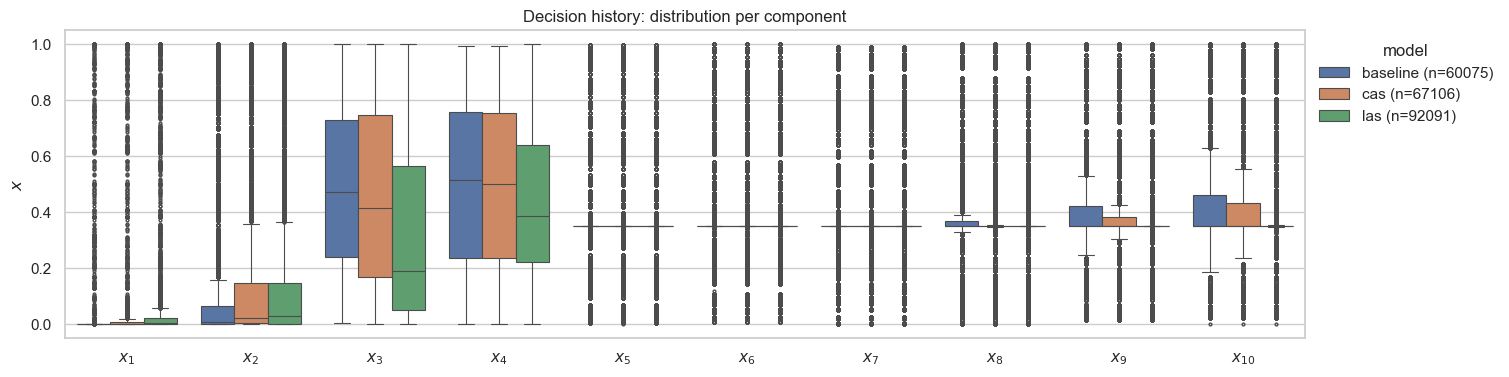

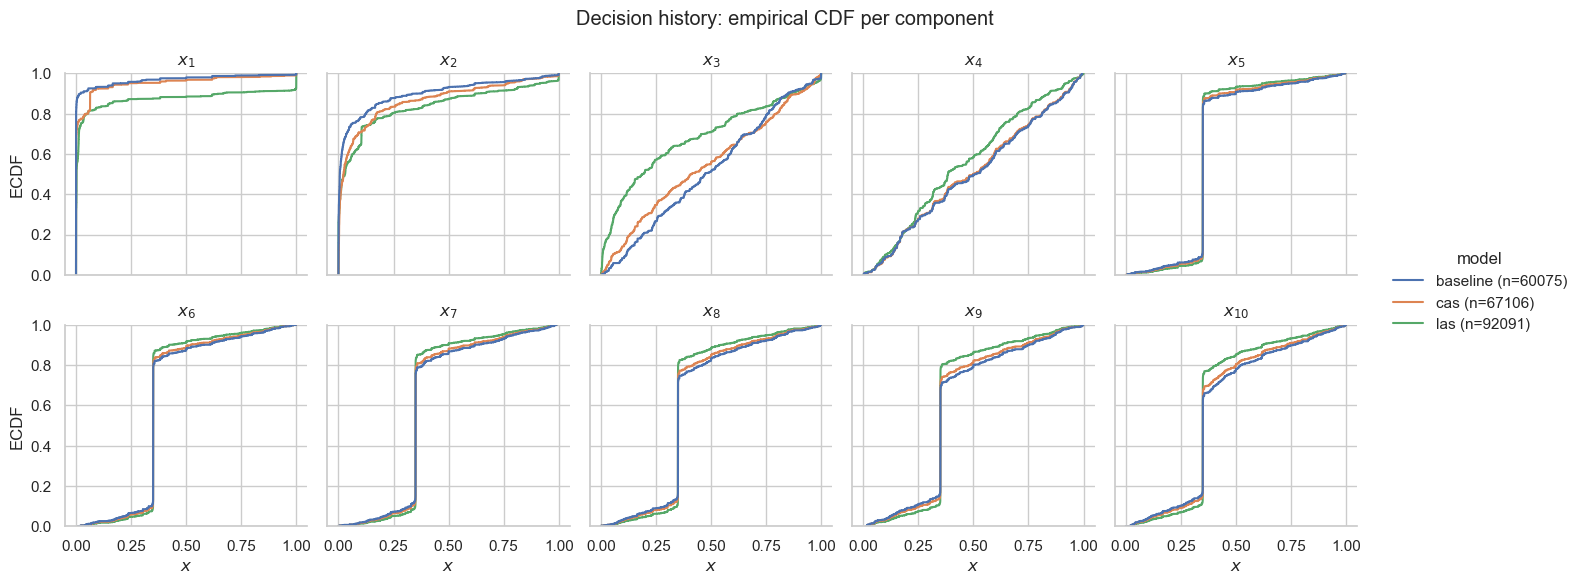

In [25]:
plot_distributions(arr, "x", "Decision history")

# Benchmark

Every configuration is solved by both models from the same seed, then scored by `evaluate()` against one shared reference point.

- **ZDT1/2/3** are 2-objective by construction, so they appear once per `n_dim` and ignore `obj_dims`.
- **DTLZ1/2** take `n_obj`, and are skipped when `n_dim <= n_obj` - there would be no tail variables left to carry `g`.
- Hypervolume is comparable **within** a row group only; the reference point differs between configurations, so never compare it across problems or dimensions.

In [26]:
# dec_dims   = [10, 20]
# obj_dims   = [2, 3, 4, 5]
# max_iter   = 50
# model_list = [LinearModel, ChoquetModel, LipschitzModel]
# prob_list  = [ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2]


# def build(problem, n_dim, n_obj):
#     """This grid cell's problem, or None if the combination does not exist: ZDT is 2-objective by
#        construction, and DTLZ needs n_dim > n_obj to leave tail variables to carry g."""
#     if problem in (ZDT1, ZDT2, ZDT3):
#         return problem(n_dim = n_dim) if n_obj == 2 else None
#     return problem(n_dim = n_dim, n_obj = n_obj) if n_dim > n_obj else None


# rows = []
# for problem, n_dim, n_obj in itertools.product(prob_list, dec_dims, obj_dims):
#     prob = build(problem, n_dim, n_obj)
#     if prob is None:
#         continue

#     fitted = [model(problem = prob, max_iter = max_iter, random_state = 42,
#                     **(dict(method = 2) if model is ChoquetModel else {}))
#               for model in model_list]
#     for m in fitted:
#         m.solve()

#     # evaluate() scores the pair against one shared reference point, and already times each solve
#     rows.append(evaluate(fitted).assign(problem = problem.__name__, n_dim = n_dim,
#                                         n_obj = prob.n_obj))
#     print(problem.__name__, f"n_dim={n_dim}", f"n_obj={prob.n_obj}",
#           dict(rows[-1]["wallclock_time"].round(1)))

# results = (pd.concat(rows).rename_axis("model").reset_index()
#              .set_index(["problem", "n_dim", "n_obj", "model"]).sort_index())
# results

In [27]:
# # hypervolume only compares within a configuration, so pick a winner per row
# hv = results["hypervolume"].unstack("model")
# hv.assign(winner = hv.idxmax(1), gap_pct = 100 * (hv.max(1) - hv.min(1)) / hv.max(1)).round(4)